# MetroBus Analytics: exploración y diagnóstico
**Darío Pérez Lorenzo · Proyecto final de Data Analytics · Periodo 2022–2024**

Mi objetivo es entender la operación antes de decidir cómo limpiar los datos.
Cada fila de viajes es una expedición, cada incidencia es un evento y cada
mantenimiento es una intervención. Las dimensiones describen entidades.

Preguntas: ¿dónde se concentra la demanda?, ¿qué franjas necesitan revisar la
puntualidad?, ¿el mayor gasto de mantenimiento refleja más intervenciones o
intervenciones más caras? El análisis es descriptivo, no prueba causalidad.

Las celdas inspeccionan los nueve CSV originales. Solo al final se aplican
correcciones documentadas sobre copias para contrastar los hallazgos.
Este notebook se edita y ejecuta directamente en Jupyter o VS Code. Selecciona el entorno Python del proyecto y utiliza «Ejecutar todo». La limpieza y la carga SQL se reproducen por separado con `python ejecutar.py`.


In [1]:
from pathlib import Path
import sys
import os
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data" / "fact_viajes.csv").exists():
    raise FileNotFoundError("Ejecuta el notebook desde la carpeta de la entrega.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache_matplotlib"))
import matplotlib.pyplot as plt
sys.path.insert(0, str(ROOT / "src"))
from preparar_datos import cargar_originales, limpiar, validar_relaciones
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": False})
tablas = cargar_originales(ROOT)

## 1. Inventario y esquema
Compruebo el volumen recibido, los tipos inferidos y las primeras filas. Un
identificador numérico es una etiqueta, no una medida sobre la que tenga sentido
calcular una media. Los CSV no preservan tipos de fecha.

In [2]:
inventario = pd.DataFrame([
    {"tabla": nombre, "filas": len(df), "columnas": df.shape[1],
     "duplicados_completos": int(df.duplicated().sum())}
    for nombre, df in tablas.items()
])
display(inventario)
for nombre, df in tablas.items():
    print("\n", nombre)
    display(df.head(3))
    df.info()

,tabla,filas,columnas,duplicados_completos
0,dim_depot,3,6,0
1,dim_linea,10,7,0
2,dim_vehiculo,45,12,0
3,dim_conductor,30,10,0
4,dim_parada,120,10,0
5,dim_tarifa,9,6,0
6,fact_viajes,50000,24,0
7,fact_incidencias,4000,16,0
8,fact_mantenimiento,876,15,0



 dim_depot


,depot_id,nombre,barrio,latitud,longitud,capacidad_vehiculos
0,1,Cochera Norte,Barrio Norte,40.440,-3.720,20
1,2,Cochera Central,Centro,40.418,-3.700,15
2,3,Cochera Sur,Barrio Sur,40.395,-3.695,12


<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   depot_id             3 non-null      int64  
 1   nombre               3 non-null      str    
 2   barrio               3 non-null      str    
 3   latitud              3 non-null      float64
 4   longitud             3 non-null      float64
 5   capacidad_vehiculos  3 non-null      int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 276.0 bytes

 dim_linea


,linea_id,codigo,nombre,tipo,km_recorrido,n_paradas,frecuencia_min
0,1,L1,Centro - Aeropuerto,Urbana,18.4,32,12
1,2,L2,Universidad - Hospital,Urbana,11.2,21,8
2,3,L3,Barrio Norte - Estacion,Urbana,9.7,18,10


<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   linea_id        10 non-null     int64  
 1   codigo          10 non-null     str    
 2   nombre          10 non-null     str    
 3   tipo            10 non-null     str    
 4   km_recorrido    10 non-null     float64
 5   n_paradas       10 non-null     int64  
 6   frecuencia_min  10 non-null     int64  
dtypes: float64(1), int64(3), str(3)
memory usage: 692.0 bytes

 dim_vehiculo


... (10 outputs left out)

,incidencia_id,viaje_id,vehiculo_id,conductor_id,linea_id,fecha,anno,mes,hora_incidencia,tipo_incidencia,categoria,severidad,requiere_retirada,duracion_resolucion_min,vehiculo_sustituto,coste_estimado_eur
0,1,33554,39,11,4,2022-06-01,2022,6,19:11,Huelga parcial,Operacional,Alta,True,60,False,0.00
1,2,9428,21,21,6,2023-02-16,2023,2,20:42,Fallo electrico,Vehiculo,Alta,True,62,False,575.51
2,3,200,33,5,8,2022-01-20,2022,1,06:21,Accidente leve,Seguridad,Alta,True,29,True,3318.00


<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   incidencia_id            4000 non-null   int64  
 1   viaje_id                 4000 non-null   int64  
 2   vehiculo_id              4000 non-null   int64  
 3   conductor_id             4000 non-null   int64  
 4   linea_id                 4000 non-null   int64  
 5   fecha                    4000 non-null   str    
 6   anno                     4000 non-null   int64  
 7   mes                      4000 non-null   int64  
 8   hora_incidencia          4000 non-null   str    
 9   tipo_incidencia          4000 non-null   str    
 10  categoria                4000 non-null   str    
 11  severidad                4000 non-null   str    
 12  requiere_retirada        4000 non-null   bool   
 13  duracion_resolucion_min  4000 non-null   int64  
 14  vehiculo_sustituto       4000 non-n

,mantenimiento_id,vehiculo_id,depot_id,fecha_entrada,fecha_salida,anno,mes,tipo_mantenimiento,categoria,es_correctivo,dias_fuera_servicio,km_en_revision,coste_eur,proveedor,garantia_meses
0,1,1,1,2024-07-24,2024-07-25,2024,7,Cambio aceite,Preventivo,False,1,278454,218.70,TallerBus Norte,0
1,2,1,1,2023-02-08,2023-02-09,2023,2,Cambio neumaticos,Preventivo,False,1,240059,1068.93,TallerBus Norte,0
2,3,1,1,2024-10-28,2024-10-29,2024,10,Cambio neumaticos,Preventivo,False,1,493071,722.19,Taller Oficial Mercedes,0


<class 'pandas.DataFrame'>
RangeIndex: 876 entries, 0 to 875
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   mantenimiento_id     876 non-null    int64  
 1   vehiculo_id          876 non-null    int64  
 2   depot_id             876 non-null    int64  
 3   fecha_entrada        876 non-null    str    
 4   fecha_salida         876 non-null    str    
 5   anno                 876 non-null    int64  
 6   mes                  876 non-null    int64  
 7   tipo_mantenimiento   876 non-null    str    
 8   categoria            861 non-null    str    
 9   es_correctivo        876 non-null    bool   
 10  dias_fuera_servicio  876 non-null    int64  
 11  km_en_revision       876 non-null    int64  
 12  coste_eur            876 non-null    float64
 13  proveedor            876 non-null    str    
 14  garantia_meses       876 non-null    int64  
dtypes: bool(1), float64(1), int64(8), str(5)
memory usa

## 2. Valores ausentes: frecuencia y porcentaje
Distingo celdas nulas de filas afectadas. El porcentaje por columna usa como
denominador las filas de su tabla, no el total de celdas. Un cero observado
no equivale a un valor desconocido.

In [3]:
perfil_nulos = pd.DataFrame([
    {"tabla": nombre, "campo": campo, "nulos": int(total),
     "porcentaje": round(100 * total / len(df), 3)}
    for nombre, df in tablas.items()
    for campo, total in df.isna().sum().items()
])
display(perfil_nulos[perfil_nulos.nulos.gt(0)])
display(pd.DataFrame([
    {"tabla": n, "filas_con_nulos": int(d.isna().any(axis=1).sum()),
     "pct_filas_afectadas": round(d.isna().any(axis=1).mean()*100, 3)}
    for n, d in tablas.items()
]))
(ROOT / "resultados").mkdir(exist_ok=True)
perfil_nulos.to_csv(ROOT / "resultados" / "eda_nulos.csv", index=False)

,tabla,campo,nulos,porcentaje
16,dim_vehiculo,combustible,1,2.222
28,dim_conductor,antiguedad_anos,1,3.333
39,dim_parada,latitud,1,0.833
41,dim_parada,accesible_silla,1,0.833
68,fact_viajes,pasajeros_subidos,40,0.080
73,fact_viajes,consumo,1065,2.130
99,fact_mantenimiento,categoria,15,1.712


,tabla,filas_con_nulos,pct_filas_afectadas
0,dim_depot,0,0.000
1,dim_linea,0,0.000
2,dim_vehiculo,1,2.222
3,dim_conductor,1,3.333
4,dim_parada,2,1.667
5,dim_tarifa,0,0.000
6,fact_viajes,1104,2.208
7,fact_incidencias,0,0.000
8,fact_mantenimiento,15,1.712


### ¿Hay un patrón de ausencia?
Comparo el porcentaje de consumo y pasajeros ausentes por año, línea, franja y
vehículo. Comparar porcentajes evita confundir tamaño de grupo con mala calidad.
Estas diferencias descriptivas no bastan para afirmar que los nulos sean aleatorios.

Patrón por anno


,filas,consumo_ausente_pct,pasajeros_ausentes_pct
anno,,,
2024,16693,2.282394,0.071886
2022,16674,2.159050,0.083963
2023,16633,1.947935,0.084170


Patrón por linea_id


,filas,consumo_ausente_pct,pasajeros_ausentes_pct
linea_id,,,
6,4990,2.384770,0.100200
9,5024,2.348726,0.139331
4,4840,2.314050,0.061983
3,4949,2.263083,0.060618
8,5003,2.218669,0.079952
7,5129,2.125171,0.058491
2,5073,2.089493,0.019712
10,4910,1.934827,0.061100
1,4954,1.816714,0.080743


Patrón por franja_horaria


,filas,consumo_ausente_pct,pasajeros_ausentes_pct
franja_horaria,,,
Valle manana,13667,2.275554,0.051218
Manana punta,8958,2.176825,0.044653
Noche,6894,2.146794,0.101538
Tarde,7266,2.133223,0.082576
Tarde punta,11213,1.944172,0.124855
Madrugada,2002,1.898102,0.099900


Patrón por vehiculo_id


,filas,consumo_ausente_pct,pasajeros_ausentes_pct
vehiculo_id,,,
23,1190,9.243697,0.168067
39,1190,8.991597,0.084034
9,1191,8.816121,0.167926
37,1190,8.571429,0.084034
7,1191,8.564232,0.083963
14,1191,8.228380,0.083963
29,1190,8.067227,0.000000
24,1190,7.815126,0.000000
8,1191,7.220823,0.000000


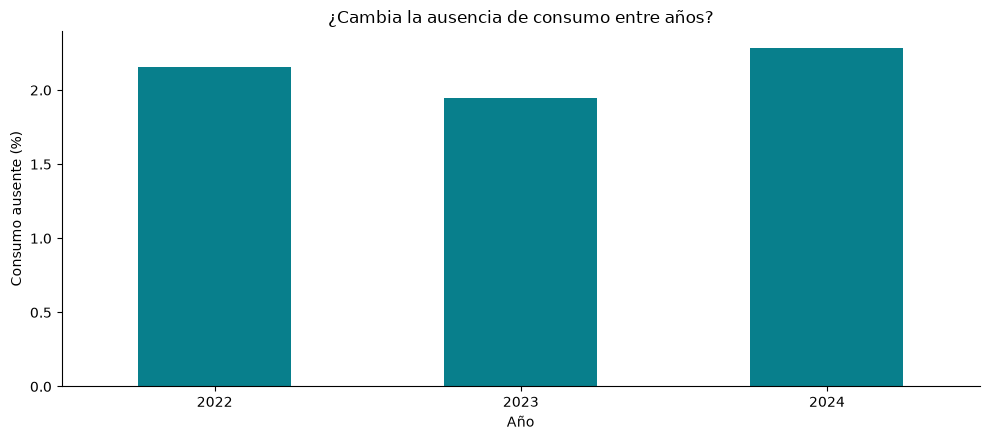

In [4]:
viajes = tablas["fact_viajes"]
patrones = []
for grupo in ["anno", "linea_id", "franja_horaria", "vehiculo_id"]:
    p = viajes.groupby(grupo).agg(
        filas=("viaje_id", "size"),
        consumo_ausente_pct=("consumo", lambda s: s.isna().mean()*100),
        pasajeros_ausentes_pct=("pasajeros_subidos", lambda s: s.isna().mean()*100)
    )
    print("Patrón por", grupo)
    display(p.sort_values("consumo_ausente_pct", ascending=False))
    patrones.append(p.reset_index().rename(columns={grupo:"grupo"}).assign(dimension=grupo))
pd.concat(patrones).to_csv(ROOT / "resultados" / "eda_patrones_nulos.csv", index=False)
fig, ax = plt.subplots()
p = viajes.groupby("anno").consumo.apply(lambda s: s.isna().mean()*100)
p.plot.bar(ax=ax, color="#087F8C", rot=0)
ax.set(title="¿Cambia la ausencia de consumo entre años?", xlabel="Año", ylabel="Consumo ausente (%)")
plt.tight_layout(); plt.show()

## 3. Estadísticos, distribuciones y valores extremos
Uso el criterio de Tukey: valores fuera de [Q1 − 1,5·IQR, Q3 + 1,5·IQR], donde
IQR = Q3 − Q1. Es una señal para revisar, no una orden automática de borrado.
Un coste positivo alto puede ser una reparación importante. El valor -99 en
retrasos necesita contrastarse con las horas de salida antes de corregirse.

,count,mean,std,min,1%,25%,50%,75%,99%,max
pasajeros_subidos,49960.0,61.283907,36.847517,1.000,4.000,30.000,56.000,91.000,156.0000,184.000
retraso_salida_min,50000.0,3.892180,6.763090,-99.000,-1.000,1.000,2.000,5.000,25.0000,50.000
ocupacion_pct,50000.0,0.455362,0.264251,0.005,0.031,0.227,0.422,0.688,0.9540,0.995
km_recorridos,50000.0,13.910457,4.999930,2.200,7.300,9.700,12.600,18.400,23.5000,23.500
consumo,48935.0,7.695104,6.221862,0.550,1.630,3.600,5.340,9.080,28.8966,32.860


,count,mean,std,min,1%,25%,50%,75%,99%,max
coste_eur,876.0,742.520879,924.806659,-4083.03,-807.5475,237.7125,455.085,922.1,4703.0975,4987.72
dias_fuera_servicio,876.0,1.898402,1.963658,0.00,0.0000,1.0000,1.000,3.0,10.0000,10.00


,count,mean,std,min,1%,25%,50%,75%,99%,max
anno_fabricacion,45.0,2020.822222,12.227556,2014.0,2014.00,2017.0,2019.0,2021.0,2066.00,2099.0
km_totales,45.0,361823.533333,157356.850166,-500.0,34161.44,274345.0,379164.0,495798.0,592064.92,596622.0


,tabla,campo,Q1,Q3,limite_inferior,limite_superior,extremos_IQR,porcentaje_no_nulos
0,fact_viajes,pasajeros_subidos,30.0000,91.000,-61.50000,182.50000,4,0.008006
1,fact_viajes,retraso_salida_min,1.0000,5.000,-5.00000,11.00000,4227,8.454000
2,fact_viajes,ocupacion_pct,0.2270,0.688,-0.46450,1.37950,0,0.000000
3,fact_viajes,km_recorridos,9.7000,18.400,-3.35000,31.45000,0,0.000000
4,fact_viajes,consumo,3.6000,9.080,-4.62000,17.30000,4863,9.937672
5,fact_mantenimiento,coste_eur,237.7125,922.100,-788.86875,1948.68125,70,7.990868
6,fact_mantenimiento,dias_fuera_servicio,1.0000,3.000,-2.00000,6.00000,37,4.223744
7,dim_vehiculo,anno_fabricacion,2017.0000,2021.000,2011.00000,2027.00000,1,2.222222
8,dim_vehiculo,km_totales,274345.0000,495798.000,-57834.50000,827977.50000,0,0.000000


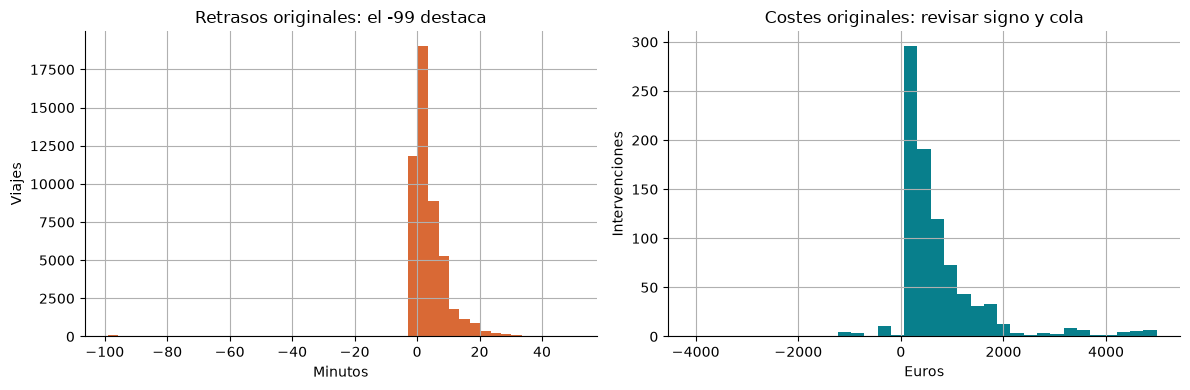

In [5]:
variables = {"fact_viajes": ["pasajeros_subidos", "retraso_salida_min", "ocupacion_pct", "km_recorridos", "consumo"],
             "fact_mantenimiento": ["coste_eur", "dias_fuera_servicio"],
             "dim_vehiculo": ["anno_fabricacion", "km_totales"]}
extremos = []
for tabla, campos in variables.items():
    display(tablas[tabla][campos].describe(percentiles=[.01, .25, .5, .75, .99]).T)
    for campo in campos:
        s = tablas[tabla][campo].dropna()
        q1, q3 = s.quantile([.25, .75]); iqr = q3-q1
        bajo, alto = q1-1.5*iqr, q3+1.5*iqr
        n = int((s.lt(bajo) | s.gt(alto)).sum())
        extremos.append({"tabla": tabla, "campo": campo, "Q1": q1, "Q3": q3,
                         "limite_inferior": bajo, "limite_superior": alto,
                         "extremos_IQR": n, "porcentaje_no_nulos": 100*n/len(s)})
extremos = pd.DataFrame(extremos)
display(extremos)
extremos.to_csv(ROOT / "resultados" / "eda_outliers.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
viajes.retraso_salida_min.hist(bins=45, ax=axes[0], color="#D96935")
axes[0].set(title="Retrasos originales: el -99 destaca", xlabel="Minutos", ylabel="Viajes")
tablas["fact_mantenimiento"].coste_eur.hist(bins=35, ax=axes[1], color="#087F8C")
axes[1].set(title="Costes originales: revisar signo y cola", xlabel="Euros", ylabel="Intervenciones")
plt.tight_layout(); plt.show()

Consumo mezcla vehículos con tecnologías distintas y no tiene unidad documentada.
Por eso no interpreto un IQR global como prueba de ineficiencia. También inspecciono
su distribución por combustible. El gráfico detecta patrones de registro; no
permite comparar litros y kWh ni ordenar tecnologías por eficiencia energética.

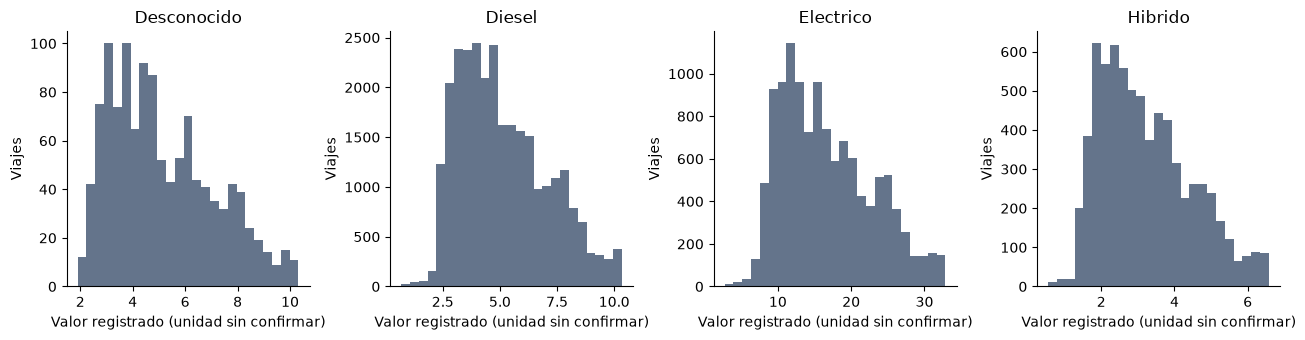

In [6]:
vista_consumo = viajes.merge(tablas["dim_vehiculo"][["vehiculo_id", "combustible"]],
                            on="vehiculo_id", validate="many_to_one")
vista_consumo["combustible"] = vista_consumo.combustible.replace({"diesel":"Diesel"}).fillna("Desconocido")
grupos = list(vista_consumo.groupby("combustible"))
fig, axes = plt.subplots(1, len(grupos), figsize=(13, 3.5))
for ax, (combustible, datos) in zip(axes, grupos):
    ax.hist(datos.consumo.dropna(), bins=25, color="#64748B")
    ax.set(title=combustible, xlabel="Valor registrado (unidad sin confirmar)", ylabel="Viajes")
plt.tight_layout(); plt.show()

## 4. Dominios, categorías y relaciones
Las claves se validan por separado de los duplicados completos. También compruebo
que los datos redundantes de una incidencia concuerden con su viaje. Un JOIN
muchos-a-uno se valida para evitar multiplicar las filas de los hechos.

In [7]:
display(validar_relaciones(tablas))
for tabla, campo in [("dim_vehiculo","combustible"), ("dim_conductor","turno_habitual"),
                     ("dim_parada","barrio"), ("fact_viajes","dia_semana"),
                     ("fact_mantenimiento","categoria")]:
    print(tabla, campo)
    display(tablas[tabla][campo].value_counts(dropna=False).to_frame("filas"))
cruce = tablas["fact_incidencias"].merge(viajes[["viaje_id","linea_id","vehiculo_id","conductor_id","fecha"]],
                     on="viaje_id", suffixes=("_incidencia","_viaje"), validate="many_to_one")
display(pd.Series({campo: int(cruce[campo+"_incidencia"].ne(cruce[campo+"_viaje"]).sum())
                   for campo in ["linea_id","vehiculo_id","conductor_id","fecha"]}, name="discordancias"))
vehiculos, paradas = tablas["dim_vehiculo"], tablas["dim_parada"]
reglas = {
    "Retraso -99": viajes.retraso_salida_min.eq(-99).sum(),
    "Coste negativo": tablas["fact_mantenimiento"].coste_eur.lt(0).sum(),
    "Latitud inválida": (paradas.latitud.notna() & ~paradas.latitud.between(-90,90)).sum(),
    "Kilometraje acumulado negativo": vehiculos.km_totales.lt(0).sum(),
    "Fabricación posterior a incorporación": vehiculos.anno_fabricacion.gt(vehiculos.anno_incorporacion).sum(),
    "Ocupación fuera de 0–1": (~viajes.ocupacion_pct.between(0,1)).sum(),
}
display(pd.Series(reglas, name="filas_afectadas"))

,regla,incumplimientos
0,PK dim_depot.depot_id,0
1,PK dim_linea.linea_id,0
2,PK dim_vehiculo.vehiculo_id,0
3,PK dim_conductor.conductor_id,0
4,PK dim_parada.parada_id,0
5,PK dim_tarifa.tarifa_id,0
6,PK fact_viajes.viaje_id,0
7,PK fact_incidencias.incidencia_id,0
8,PK fact_mantenimiento.mantenimiento_id,0
9,FK dim_vehiculo.depot_id -> dim_depot.depot_id,0


dim_vehiculo combustible


,filas
combustible,
Diesel,25
Electrico,12
Hibrido,6
diesel,1
NaN,1


dim_conductor turno_habitual


,filas
turno_habitual,
Noche (22-06h),8
Partido,7
Manana (06-14h),7
Tarde (14-22h),7
manana,1


dim_parada barrio


... (3 outputs left out)

fact_mantenimiento categoria


,filas
categoria,
Preventivo,359
Correctivo,332
Legal,85
Estetico,85
NaN,15


linea_id        0
vehiculo_id     0
conductor_id    0
fecha           0
Name: discordancias, dtype: int64

Retraso -99                              80
Coste negativo                           25
Latitud inválida                          1
Kilometraje acumulado negativo            1
Fabricación posterior a incorporación     1
Ocupación fuera de 0–1                    0
Name: filas_afectadas, dtype: int64

## 5. Cobertura temporal y coherencia de la flota
Viajes e incidencias cubren 2022–2024. Mantenimiento contiene 47 entradas en
2025. Se conservan para trazabilidad, pero el reporting usa fecha de entrada
hasta 2024-12-31. El estado actual de una dimensión no acredita su estado histórico.

In [8]:
rangos = []
for tabla, campos in {"fact_viajes":["fecha"], "fact_incidencias":["fecha"],
                      "fact_mantenimiento":["fecha_entrada","fecha_salida"]}.items():
    for campo in campos:
        s = pd.to_datetime(tablas[tabla][campo], errors="coerce")
        rangos.append({"tabla":tabla, "campo":campo, "min":s.min(), "max":s.max(),
                       "nulos_tras_conversion":s.isna().sum(), "posteriores_2024":s.gt("2024-12-31").sum()})
display(pd.DataFrame(rangos))
anio_alta = viajes.vehiculo_id.map(vehiculos.set_index("vehiculo_id").anno_incorporacion)
print("Viajes anteriores al año de incorporación:", int(viajes.anno.lt(anio_alta).sum()))

,tabla,campo,min,max,nulos_tras_conversion,posteriores_2024
0,fact_viajes,fecha,2022-01-01,2024-12-31,0,0
1,fact_incidencias,fecha,2022-01-01,2024-12-31,0,0
2,fact_mantenimiento,fecha_entrada,2022-01-02,2025-01-01,0,47
3,fact_mantenimiento,fecha_salida,2022-01-02,2025-01-11,0,47


Viajes anteriores al año de incorporación: 7941


## 6. Hallazgos de negocio con correcciones trazables
Aplico en memoria las reglas del módulo `preparar_datos.py`. La tabla original
sigue intacta. Se reconstruyen 80 retrasos desde las horas real y programada,
se normalizan etiquetas y se conservan nulos sin evidencia. Los costes negativos
quedan fuera del subtotal válido, con su cobertura explícita.

,tabla,campo,tipo_problema,frecuencia,decision,justificacion
0,dim_vehiculo,combustible,Categoría inconsistente,1,{'diesel': 'Diesel'},Unificar etiquetas equivalentes; no cambia su ...
1,dim_conductor,turno_habitual,Categoría inconsistente,1,{'manana': 'Manana (06-14h)'},Unificar etiquetas equivalentes; no cambia su ...
2,dim_parada,barrio,Categoría inconsistente,2,"{'centro': 'Centro', 'BARRIO NORTE': 'Barrio N...",Unificar etiquetas equivalentes; no cambia su ...
3,fact_viajes,dia_semana,Etiqueta inconsistente,30,Recalcular desde fecha con un mapa explícito.,Fecha validada es la fuente; evita etiquetas d...
4,dim_vehiculo,combustible,Nulo,1,Inferir solo con categoría única por modelo; m...,Correspondencia unívoca observada; una categor...
5,fact_mantenimiento,categoria,Nulo,15,Inferir solo con categoría única por tipo_mant...,Correspondencia unívoca observada; una categor...
6,dim_conductor,antiguedad_anos,Nulo,1,"Calcular 2024 - anno_incorporacion, con bandera.",Antigüedad en años enteros al cierre; coincide...
7,dim_vehiculo,anno_fabricacion,Fuera de dominio,1,Conservar original y bandera; valor analítico ...,No existe evidencia para reconstruir el valor ...
8,dim_vehiculo,km_totales,Fuera de dominio,1,Conservar original y bandera; valor analítico ...,No existe evidencia para reconstruir el valor ...
9,dim_parada,latitud,Fuera de dominio,1,"999 pasa a nulo, con original y bandera.",Una latitud debe estar entre -90 y 90 grados.


,pasajeros,viajes,conocidos,ocupacion,pasajeros_por_viaje_informado
franja_horaria,,,,,
Madrugada,76721,2002,2000,0.282853,38.3605
Manana punta,861477,8958,8954,0.713936,96.211414
Noche,264834,6894,6887,0.286169,38.454189
Tarde,272917,7266,7260,0.279573,37.591873
Tarde punta,1069269,11213,11199,0.710042,95.478971
Valle manana,516526,13667,13660,0.281003,37.813031


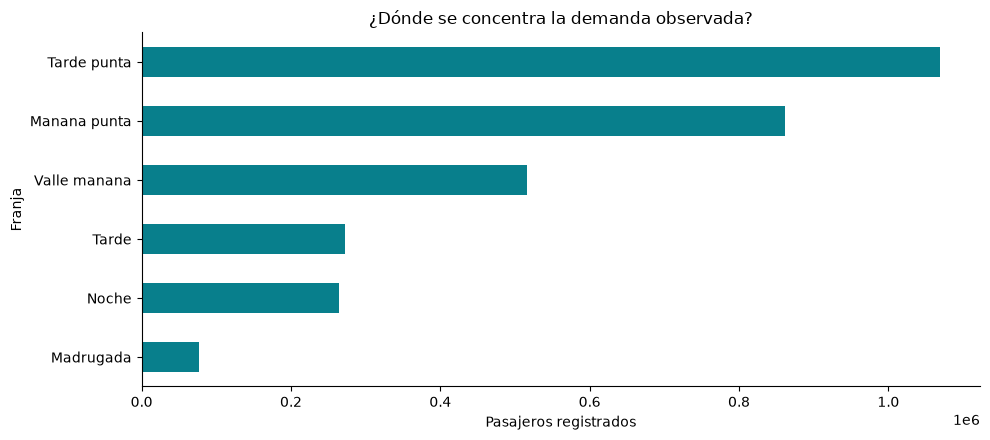

Franjas punta: 63.06% de los pasajeros observados.
Cobertura de pasajeros: 99.92%.


In [9]:
limpias, decisiones = limpiar(tablas)
display(decisiones)
v = limpias["fact_viajes"]
m = limpias["fact_mantenimiento"].query("en_periodo").copy()
demanda = v.groupby("franja_horaria").agg(pasajeros=("pasajeros_subidos","sum"),
                     viajes=("viaje_id","size"), conocidos=("pasajeros_subidos","count"),
                     ocupacion=("ocupacion_pct","mean"))
demanda["pasajeros_por_viaje_informado"] = demanda.pasajeros / demanda.conocidos
display(demanda)
demanda.pasajeros.sort_values().plot.barh(color="#087F8C")
plt.title("¿Dónde se concentra la demanda observada?")
plt.xlabel("Pasajeros registrados"); plt.ylabel("Franja")
plt.tight_layout(); plt.show()
punta = demanda.index.isin(["Manana punta","Tarde punta"])
cuota = demanda.loc[punta,"pasajeros"].sum()/demanda.pasajeros.sum()*100
print(f"Franjas punta: {cuota:.2f}% de los pasajeros observados.")
print(f"Cobertura de pasajeros: {v.pasajeros_subidos.notna().mean()*100:.2f}%.")

**Interpretación.** Las franjas punta concentran aproximadamente el 63 % de los
pasajeros. El promedio por viaje informado permite contrastar si la demanda
alta se explica solo por más expediciones. Propongo revisar capacidad por línea
y franja antes de aumentar servicios de forma uniforme. Hipótesis a probar:
ajustar frecuencia en las combinaciones con mayor ocupación mejora el servicio.

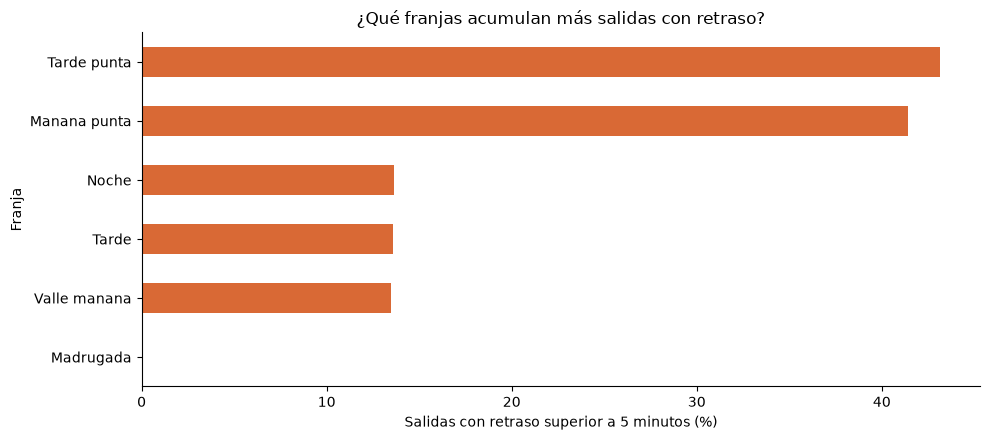

Retrasados tras corregir -99: 24.632%
Retrasados si tratásemos -99 como puntual: 24.602%


In [10]:
puntualidad = v.groupby("franja_horaria").es_retrasado.mean().mul(100).sort_values()
puntualidad.plot.barh(color="#D96935")
plt.title("¿Qué franjas acumulan más salidas con retraso?")
plt.xlabel("Salidas con retraso superior a 5 minutos (%)"); plt.ylabel("Franja")
plt.tight_layout(); plt.show()
print(f"Retrasados tras corregir -99: {v.es_retrasado.mean()*100:.3f}%")
print(f"Retrasados si tratásemos -99 como puntual: {viajes.retraso_salida_min.gt(5).mean()*100:.3f}%")

**Interpretación.** Aproximadamente una de cada cuatro salidas supera cinco
minutos de retraso. Las franjas punta reúnen demanda y retraso elevados.
Recomiendo revisar tiempos programados y márgenes de recuperación. No atribuyo
el retraso al conductor: falta contexto de tráfico y asignación del servicio.

,intervenciones,validas,coste,coste_medio,cobertura_pct
fecha_entrada,,,,,
2022,211,205,172136.79,839.691659,97.156398
2023,280,269,197878.86,735.609145,96.071429
2024,338,332,262792.80,791.544578,98.224852


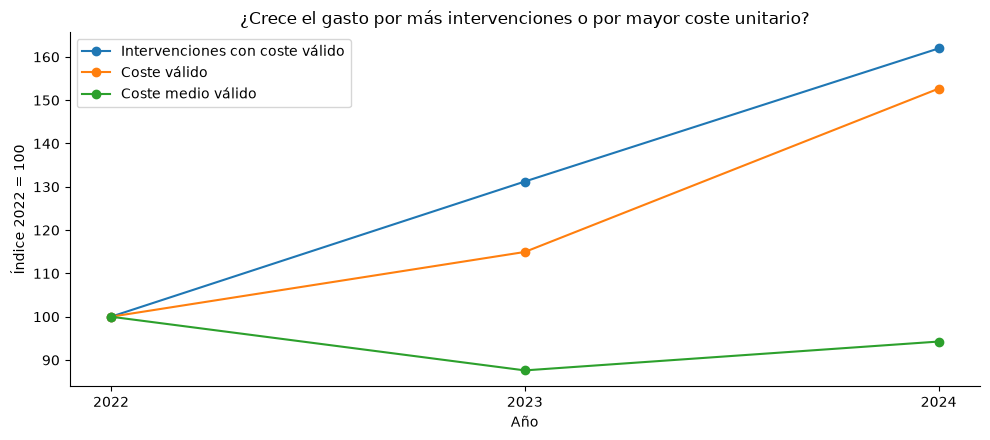

Variación 2022–2024 (%):


validas        61.951220
coste          52.665098
coste_medio    -5.733900
dtype: float64

In [11]:
anual = m.groupby(m.fecha_entrada.dt.year).agg(
    intervenciones=("mantenimiento_id","size"), validas=("coste_eur","count"),
    coste=("coste_eur","sum"), coste_medio=("coste_eur","mean"))
anual["cobertura_pct"] = anual.validas/anual.intervenciones*100
display(anual)
indice = anual[["validas","coste","coste_medio"]].div(anual.iloc[0][["validas","coste","coste_medio"]]).mul(100)
indice.rename(columns={"validas":"Intervenciones con coste válido", "coste":"Coste válido", "coste_medio":"Coste medio válido"}).plot(marker="o")
plt.title("¿Crece el gasto por más intervenciones o por mayor coste unitario?")
plt.ylabel("Índice 2022 = 100"); plt.xlabel("Año"); plt.xticks([2022,2023,2024])
plt.tight_layout(); plt.show()
print("Variación 2022–2024 (%):")
display((anual.loc[2024,["validas","coste","coste_medio"]]/anual.loc[2022,["validas","coste","coste_medio"]]-1)*100)

**Interpretación.** El subtotal de costes válidos aumenta un 52,67 %, mientras
el coste medio por intervención válida disminuye. El volumen de intervenciones
explica contablemente el crecimiento, sin demostrar por sí solo deterioro de
la flota. Conviene revisar preventivo/correctivo, exposición en kilómetros y
cobertura del registro. Hay 23 costes no utilizables dentro de 2022–2024.

## 7. Conclusiones y límites
- Nueve tablas con claves completas y sin duplicados completos. Las relaciones
  revisadas no presentan huérfanos ni discordancias incidencia-viaje.
- Los nulos originales afectan especialmente a consumo (2,13 %) y a categoría
  de mantenimiento. No hay razón para sustituir todo por cero.
- Los extremos se revisan con dominio y contexto. Se conservan reparaciones
  positivas caras y salidas anticipadas válidas. Los códigos imposibles se
  corrigen o se marcan como desconocidos según la evidencia disponible.
- 7.941 viajes son anteriores al año de incorporación declarado de su vehículo.
  Esta incoherencia limita la disponibilidad histórica y las comparaciones por
  antigüedad. La demanda observada puede analizarse, pero esa dimensión requiere
  aclaración del proveedor.
- El total de pasajeros es un recuento de subidas, no personas únicas. El dato
  tarifario predominante no permite reconstruir ingresos reales.
- El consumo carece de unidad documentada. Emisiones directas de eléctricos
  iguales a cero no equivalen a cero emisiones de ciclo de vida.
- Próximo paso: ejecutar la limpieza trazable, cargar SQL con restricciones y
  usar los mismos criterios en Tableau, gobierno y presentación.